# How the corrections change our results

The limits are set from signal-region counts: the signal yield, the background, and
the nuisances on both (`sidm/studies/limit_plotting`). This notebook measures what the
standard corrections do to those inputs, for every signal point and every simulated
background of the Condor campaign (README, "The Condor campaign"):

1. a consistency check of the campaign outputs;
2. the shift of the SR signal yields when the corrections are applied, correction by
   correction;
3. the uncertainty of each correction as a log-normal datacard nuisance, written to
   `tables/sr_correction_nuisances.csv` for every point;
4. the same for the simulated backgrounds;
5. a distribution with its correction band;
6. a remark on the SR definition that affects how these numbers are read.

All yields are read from the cutflows, whose rows carry every weight category:
`uncorrected` (genWeight only), `nominal` (all default corrections), `only_<name>`
(genWeight times one correction), the up and down variations, and
`with_photon_pixel_veto` (the pixel-veto SF, evaluated but not applied). Simulation only.

In [1]:
import os, sys, csv, warnings
import numpy as np
import hist
import matplotlib.pyplot as plt
import mplhep as hep
from matplotlib.lines import Line2D

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import corrections, utilities
from sidm.studies.corrections import corrections_study as study

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)
BLUE, ORANGE, AQUA, GRAY, BLACK = study.BLUE, study.ORANGE, study.AQUA, study.GRAY, study.BLACK
corr = corrections.Corrections("2018")
NAMES = corr.names                     # the default corrections
MONITORED = "photon_pixel_veto"
print("campaign outputs:", study.CAMPAIGN_DIR, "| default corrections:", NAMES)

campaign outputs: /store/user/scampbel/sidm_coffea_outputs/corrections_v1 | default corrections: ['pileup', 'l1_prefiring', 'muon_id', 'electron_reco']


## Samples

In [2]:
SIGNALS = study.signal_points()
BKG = [s for group in study.BACKGROUNDS.values() for s in group]
LXY = study.median_lxy()
out = study.load(SIGNALS + BKG)
CHANNELS = ["base", "2mu2e", "4mu", "2mu2e_sr", "4mu_sr"]

def sr(s):
    return study.SR[study.parse_point(s)["final_state"]]

print(f"{len(SIGNALS)} signal points, {len(BKG)} background samples")
print(f"{'signal point':34s} {'median Lxy':>11s} {'SR raw':>7s} {'SR yield':>9s}")
for s in SIGNALS:
    p = study.parse_point(s)
    if p["m_zd"] == 1.2 and p["m_phi"] in (200, 500, 1000):
        print(f"{s:34s} {LXY[s]:8.2f} cm {study.raw(out[s], sr(s)):7d} {study.yields(out[s], sr(s))['nominal']:9.4f}")

180 signal points, 20 background samples
signal point                        median Lxy  SR raw  SR yield
2Mu2E_200GeV_1p2GeV_0p048mm            0.24 cm    8330   12.0008
2Mu2E_200GeV_1p2GeV_0p48mm             2.33 cm   14670   11.2959
2Mu2E_200GeV_1p2GeV_4p8mm             23.38 cm   12579    8.8583
2Mu2E_200GeV_1p2GeV_24p0mm           107.50 cm    3597    3.2056
2Mu2E_200GeV_1p2GeV_48p0mm           172.34 cm     484    1.6010
2Mu2E_500GeV_1p2GeV_0p019mm            0.23 cm   73603   21.2910
2Mu2E_500GeV_1p2GeV_0p19mm             2.25 cm   65415   20.1265
2Mu2E_500GeV_1p2GeV_1p9mm             22.60 cm   52295   15.1287
2Mu2E_500GeV_1p2GeV_9p6mm            106.07 cm   14747    4.6470
2Mu2E_500GeV_1p2GeV_19p0mm           170.50 cm    5290    2.2724
2Mu2E_1000GeV_1p2GeV_0p0096mm          0.23 cm   58392   17.6362
2Mu2E_1000GeV_1p2GeV_0p096mm           2.25 cm   61004   16.5204
2Mu2E_1000GeV_1p2GeV_0p96mm           22.53 cm   29897   10.9911
2Mu2E_1000GeV_1p2GeV_4p8mm           105.70 cm   

The signal yields are for a cross section of 1 fb and the 2018 luminosity.

## 1. Consistency of the outputs

The histograms and the cutflows are filled from the same weights, so the integral of
any histogram with one entry per event must equal the cutflow yield after the last cut,
in every weight category. With `lj_n` (one entry per event):

In [3]:
worst = 0.0
for s in SIGNALS + BKG:
    h = out[s]["hists"]["lj_n"]
    for ch in CHANNELS:
        y = study.yields(out[s], ch)
        for cat, value in y.items():
            integral = h[{"channel": ch, "syst": cat}].sum(flow=True).value
            if value:
                worst = max(worst, abs(integral / value - 1))
print(f"largest relative difference, {len(SIGNALS) + len(BKG)} samples x {len(CHANNELS)} channels x every category: {worst:.1e}")

largest relative difference, 200 samples x 5 channels x every category: 3.4e-15


The per-event closure of the weights (each event weight rebuilt from its inputs with
the `Corrections` API) is in `00_correctionlib_tutorial.ipynb`.

## 2. What the corrections do to the signal yields

The corrected SR yield relative to the uncorrected one, and the share of each
correction, which is the `only_<name>` over `uncorrected` yield: the average of that
factor over the selected events. The photon pixel-veto SF is included to show what it
would do (`with_photon_pixel_veto` over `nominal`); it is not part of the default
weight.

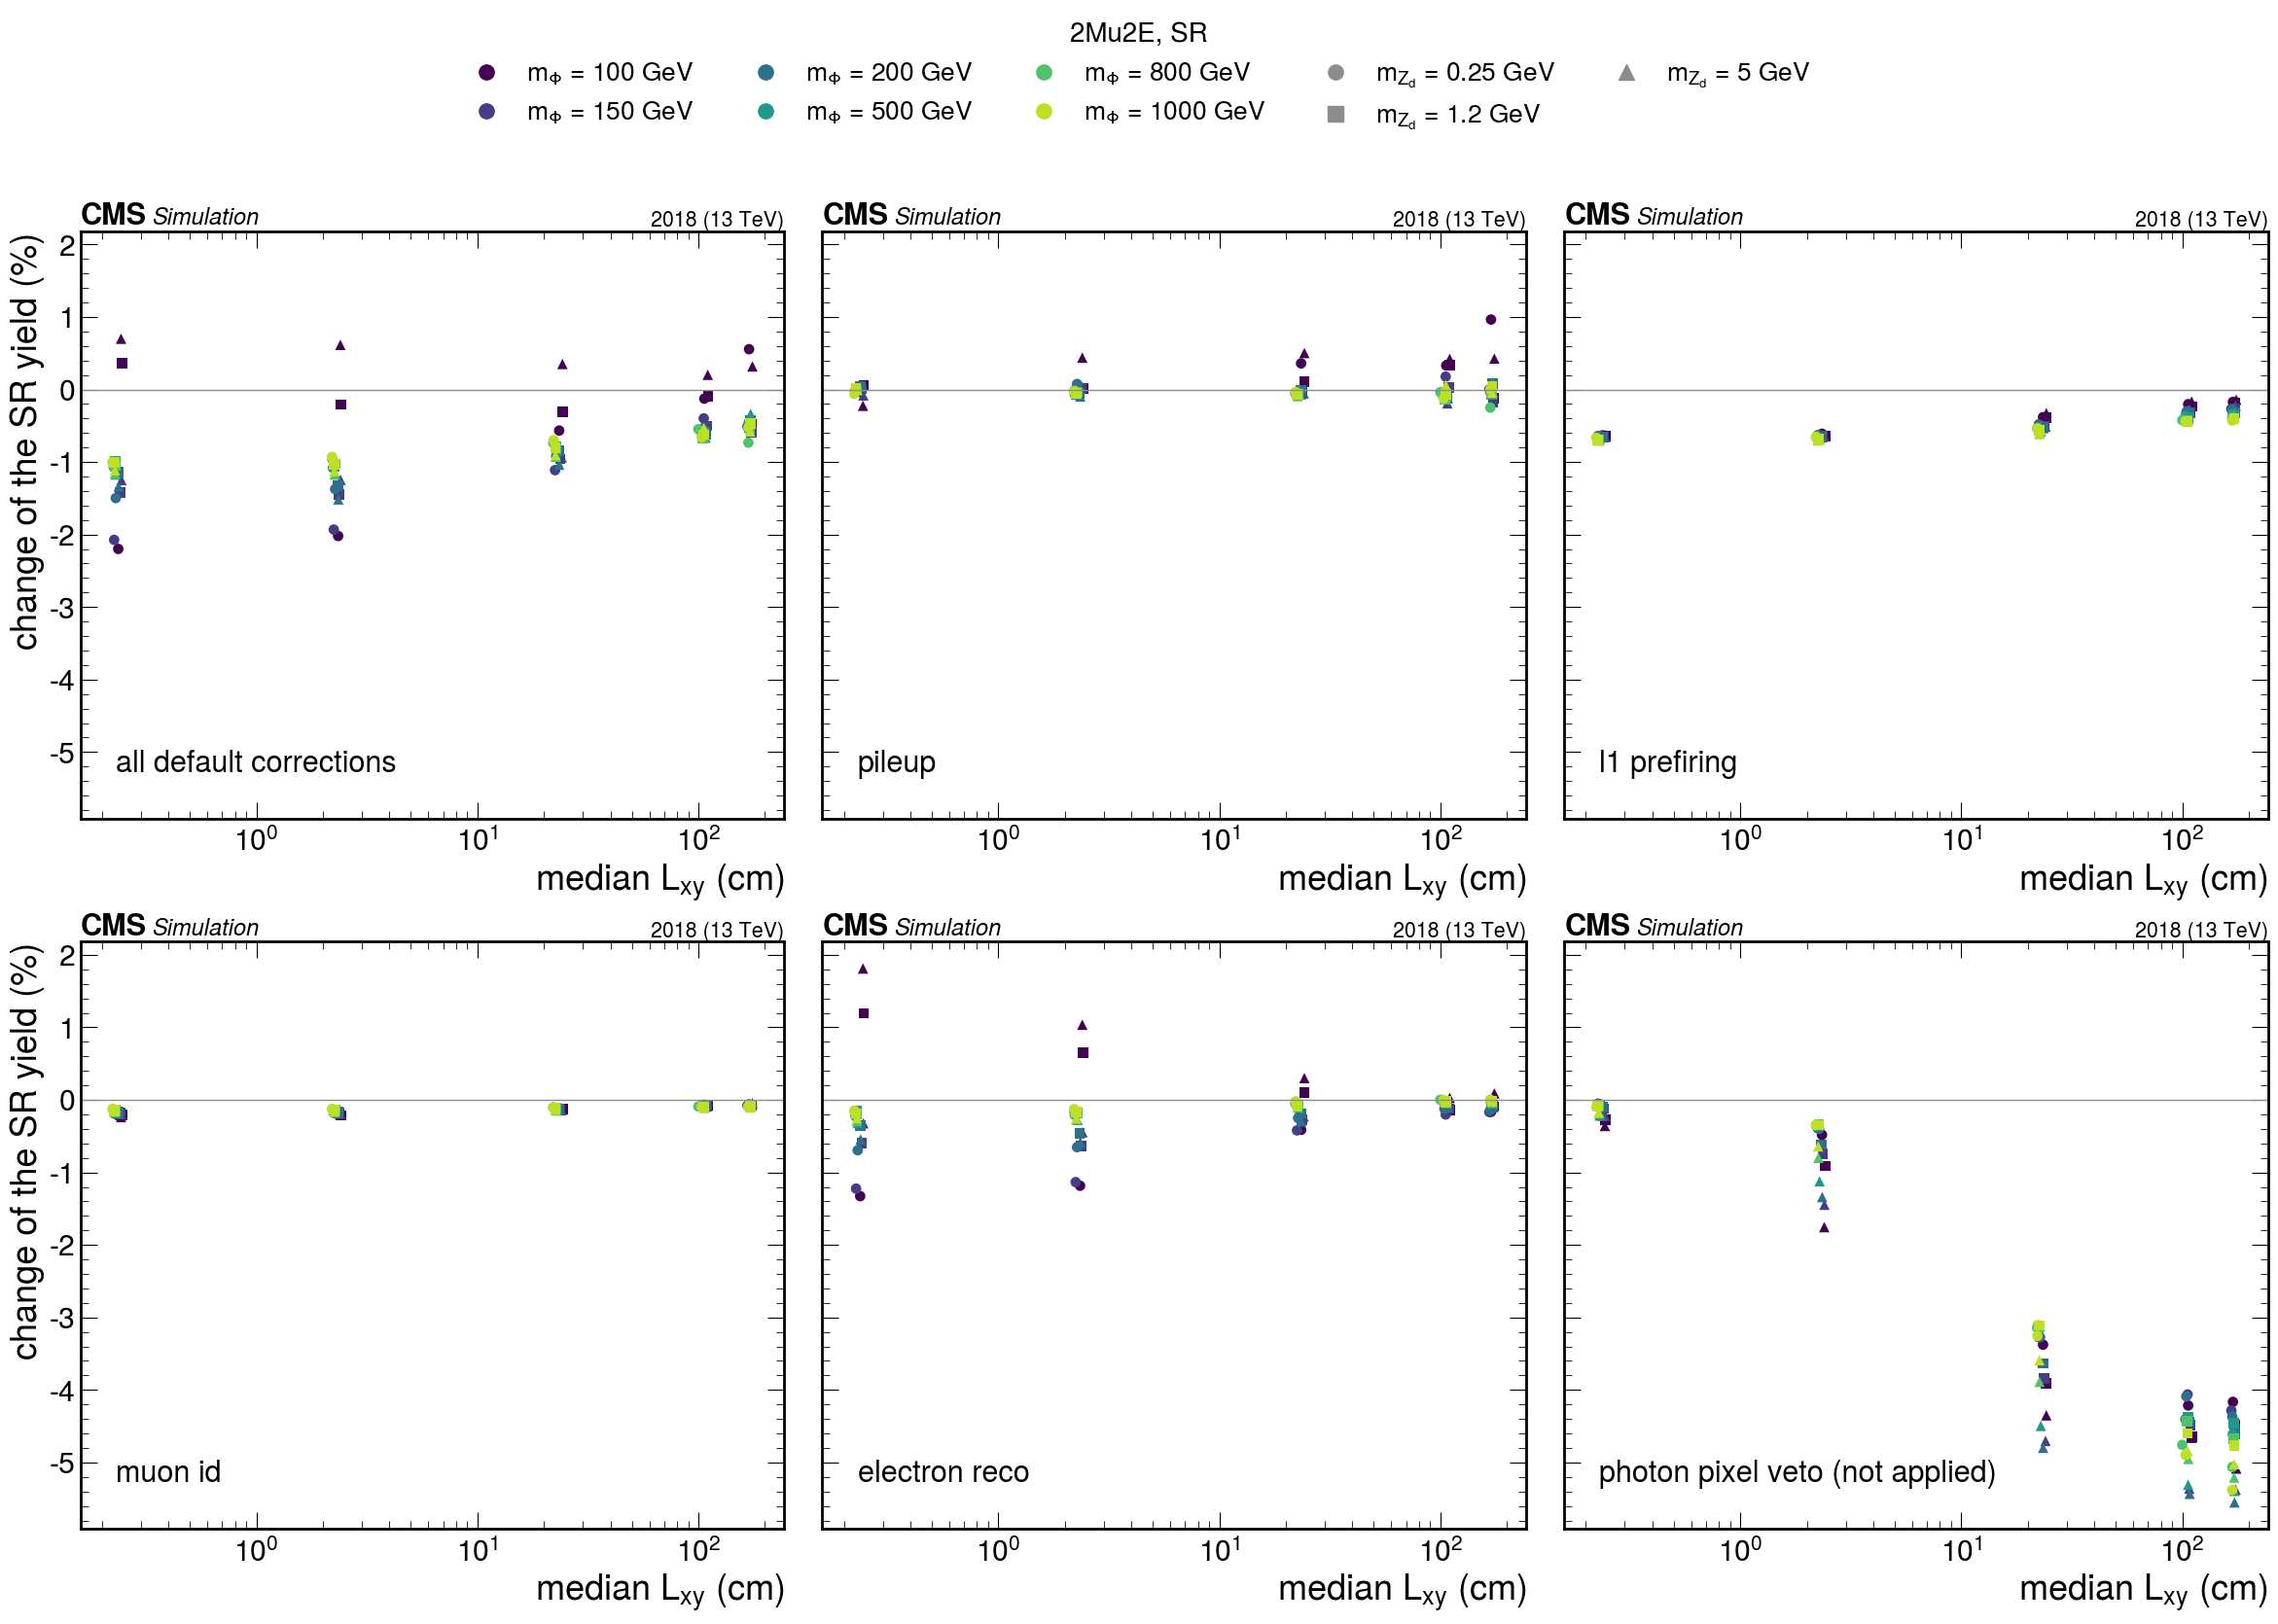

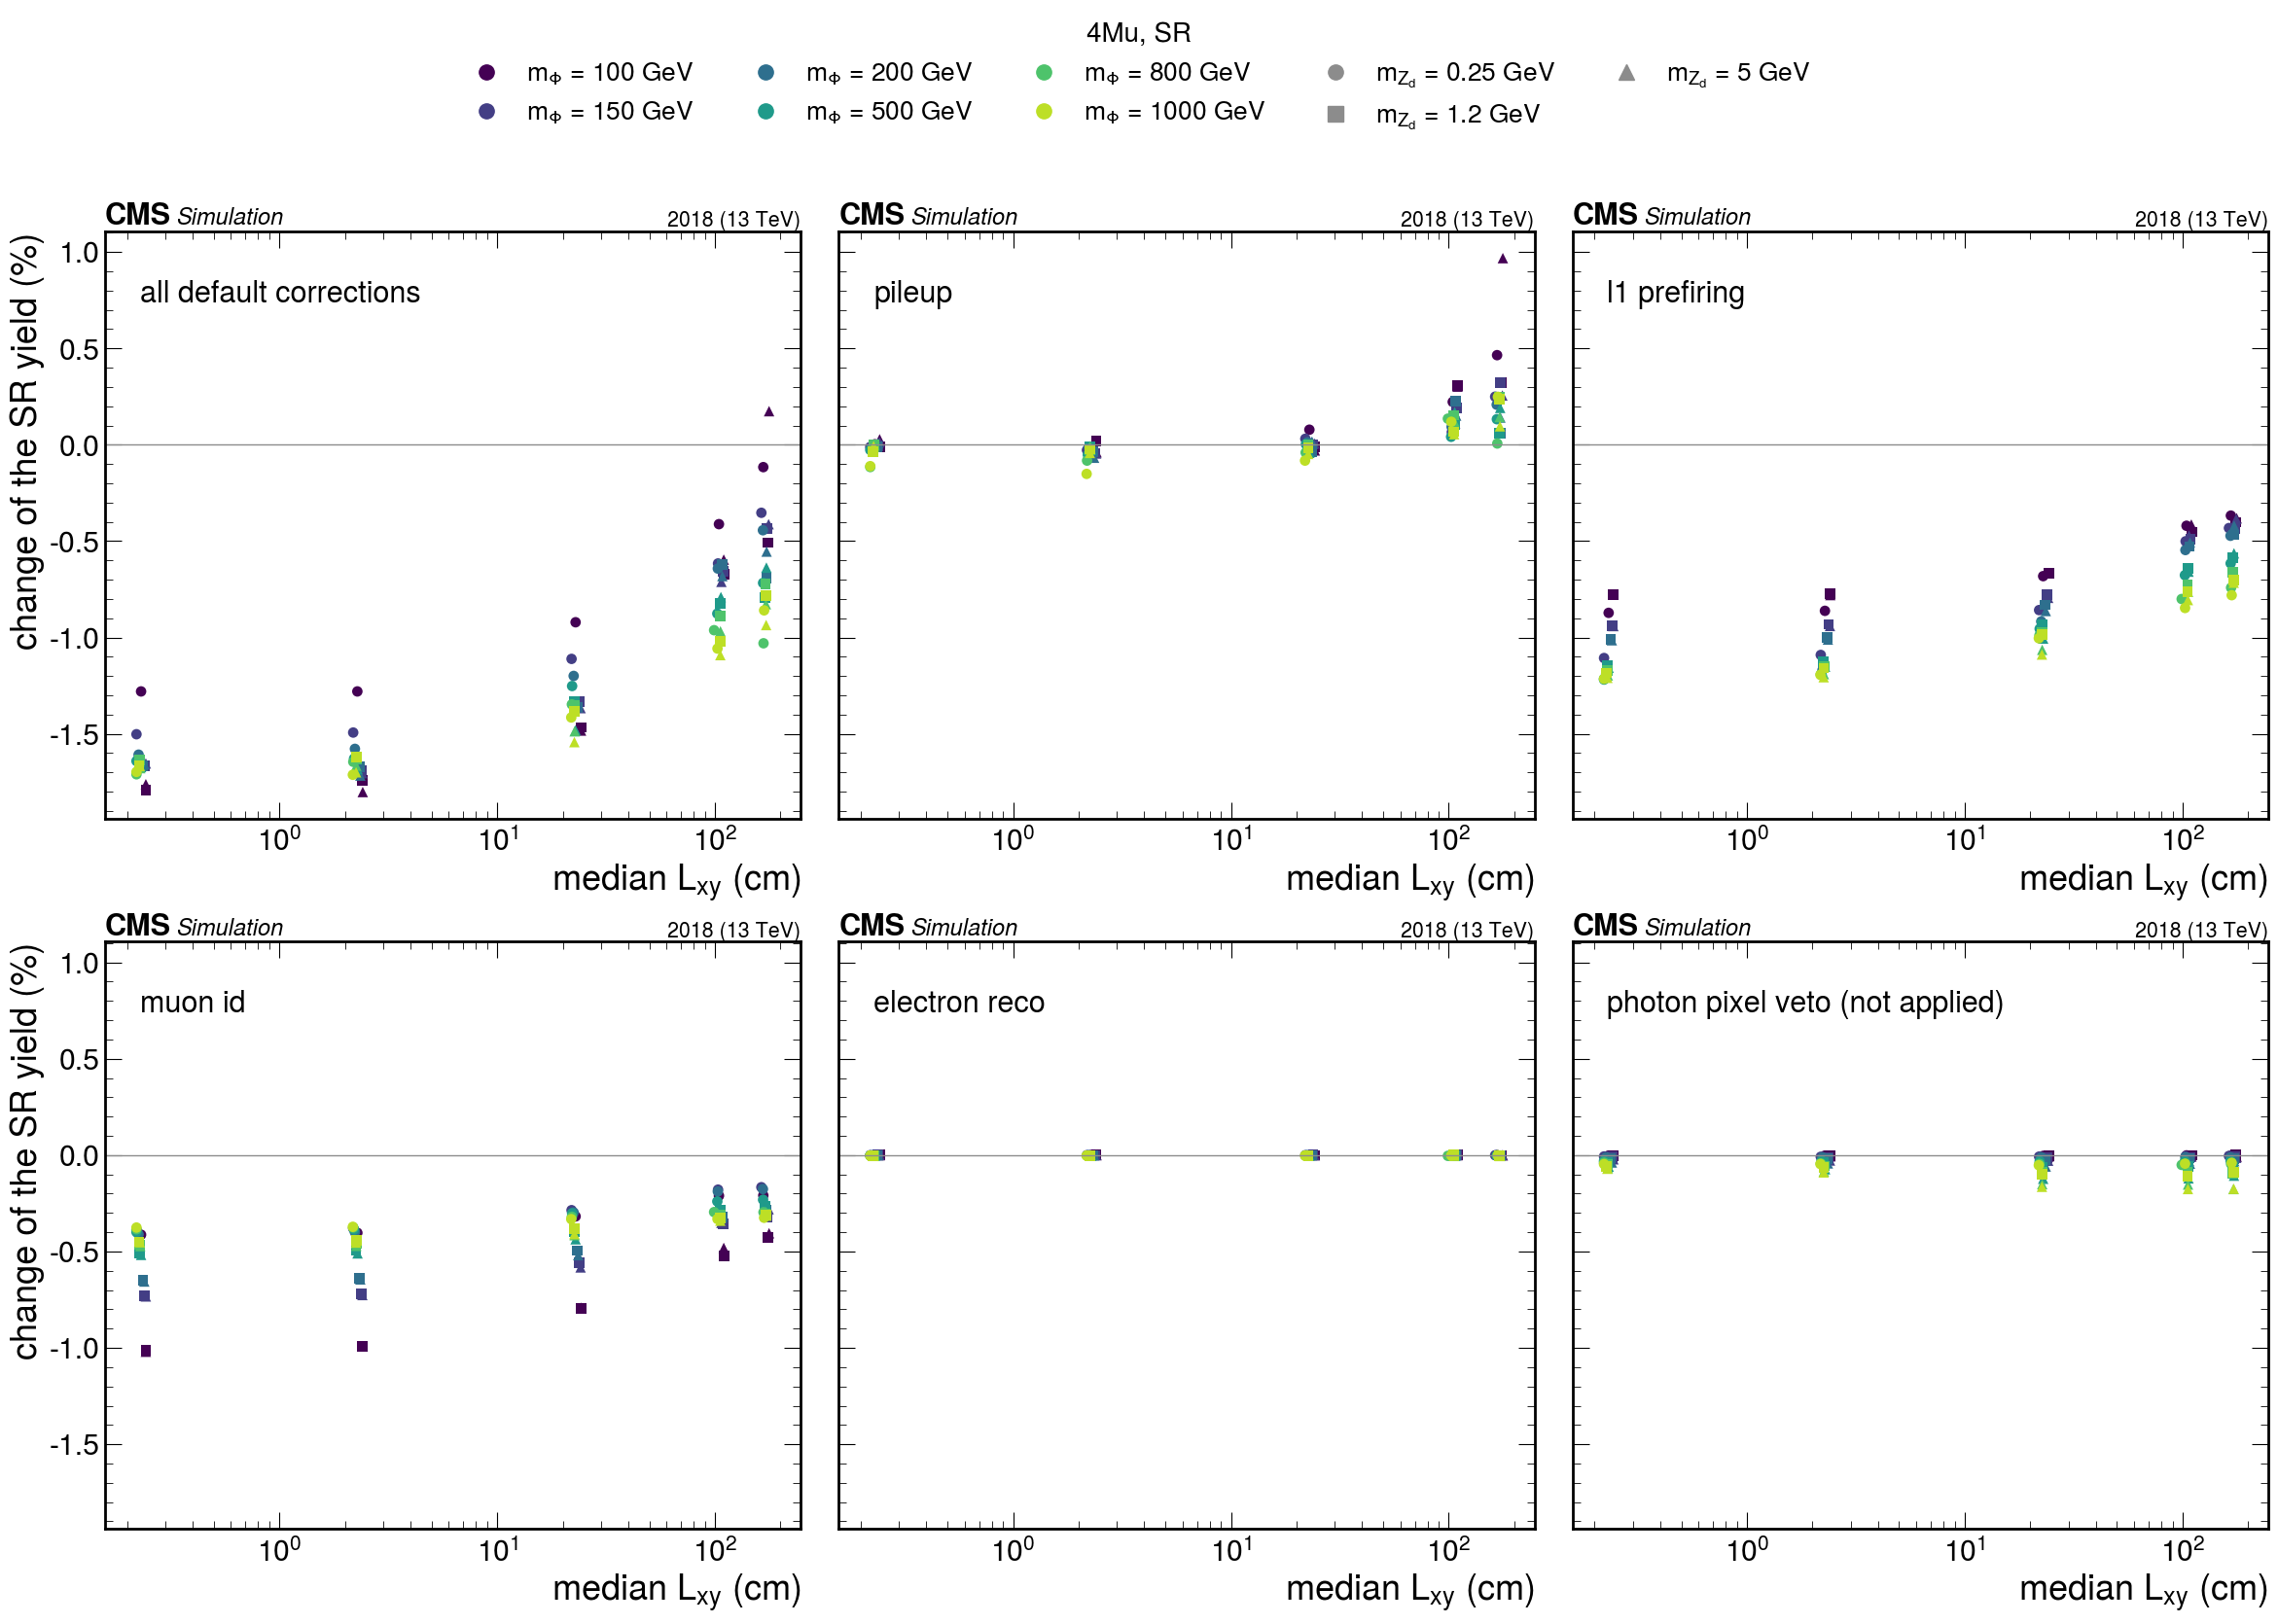

In [4]:
PANELS = NAMES + [MONITORED]
shift, unc = {}, {}
for s in SIGNALS:
    y = study.yields(out[s], sr(s))
    shift[s] = {n: y[f"only_{n}"] / y["uncorrected"] - 1 for n in NAMES}
    shift[s][MONITORED] = y[f"with_{MONITORED}"] / y["nominal"] - 1
    shift[s]["total"] = y["nominal"] / y["uncorrected"] - 1
    unc[s] = {n: (y[f"{n}Up"] / y["nominal"] - 1, y[f"{n}Down"] / y["nominal"] - 1) for n in NAMES}
    w = y[f"with_{MONITORED}"]
    unc[s][MONITORED] = (y[f"with_{MONITORED}Up"] / w - 1, y[f"with_{MONITORED}Down"] / w - 1)

MASSES = sorted({study.parse_point(s)["m_phi"] for s in SIGNALS})
MASS_COLORS = dict(zip(MASSES, plt.get_cmap("viridis")(np.linspace(0, 0.9, len(MASSES)))))
ZD_MARKERS = {0.25: "o", 1.2: "s", 5.0: "^"}

def small_multiples(values, ylabel, figname, final_state, text_y, panels):
    # one panel per correction; colour = m_Phi, marker = m_Zd
    fig, axs = plt.subplots(2, 3, figsize=(24, 15), sharey=True)
    axs = axs.ravel()
    pts = [s for s in SIGNALS if s.startswith(final_state + "_")]
    for ax, name in zip(axs, panels):
        for s in pts:
            p = study.parse_point(s)
            ax.scatter(LXY[s], 100 * values[s][name], color=MASS_COLORS[p["m_phi"]],
                       marker=ZD_MARKERS[p["m_zd"]], s=60, edgecolor="none")
        ax.axhline(0, color=GRAY, lw=1)
        ax.set_xscale("log")
        title = {"photon_pixel_veto": "photon pixel veto (not applied)", "total": "all default corrections",
                 "quadrature": "default, in quadrature"}.get(name, name.replace("_", " "))
        ax.text(0.05, text_y, title, transform=ax.transAxes, fontsize=22)
        ax.set_xlabel(r"median $L_{xy}$ (cm)")
    for ax in (axs[0], axs[3]):
        ax.set_ylabel(ylabel)
    handles = [Line2D([], [], color=MASS_COLORS[m], marker="o", ls="none", ms=11, label=rf"$m_\Phi$ = {m:g} GeV")
               for m in MASSES]
    handles += [Line2D([], [], color=GRAY, marker=mk, ls="none", ms=11, label=rf"$m_{{Z_d}}$ = {z:g} GeV")
                for z, mk in ZD_MARKERS.items()]
    fig.legend(handles=handles, loc="upper center", ncol=5, fontsize=19, bbox_to_anchor=(0.5, 1.135),
               title=f"{final_state}, SR", title_fontsize=20)
    plt.tight_layout()
    study.cms_label(list(axs))
    study.save(fig, figname)
    plt.show()

for fs in study.FINAL_STATES:
    # panel names where the points are not: below them for 2Mu2E, above them for 4Mu
    small_multiples(shift, "change of the SR yield (%)", f"impact_yield_shifts_{fs}", fs,
                    {"2Mu2E": 0.08, "4Mu": 0.88}[fs], ["total"] + PANELS)

In [5]:
def ranges(values, keys, signed=True):
    print(f"{'':24s}" + "".join(f"{fs:>22s}" for fs in study.FINAL_STATES))
    sign = "+" if signed else ""
    for k in keys:
        cols = []
        for fs in study.FINAL_STATES:
            v = [100 * values[s][k] for s in SIGNALS if s.startswith(fs + "_")]
            cols.append(f"{min(v):{sign}8.2f} to {max(v):{sign}6.2f}%")
        print(f"{k:24s}" + "".join(f"{c:>22s}" for c in cols))

print("Change of the SR yield over all points (min to max):")
ranges(shift, ["total"] + PANELS)

Change of the SR yield over all points (min to max):
                                         2Mu2E                   4Mu
total                         -2.20 to  +0.70%      -1.80 to  +0.17%
pileup                        -0.25 to  +0.96%      -0.15 to  +0.97%
l1_prefiring                  -0.71 to  -0.14%      -1.22 to  -0.37%
muon_id                       -0.24 to  -0.05%      -1.02 to  -0.17%
electron_reco                 -1.33 to  +1.81%      -0.00 to  +0.00%
photon_pixel_veto             -5.55 to  -0.05%      -0.18 to  +0.00%


Over the whole grid the default corrections change the SR yields by $-2.2$ to $+0.7$%
for 2Mu2E (median $-0.7$%) and $-1.8$ to $+0.2$% for 4Mu (median $-1.4$%).

* The **L1 prefiring** weight lowers every point, by 0.1 to 0.7% (2Mu2E) and 0.4 to 1.2%
  (4Mu): it grows with the number of PF muons and shrinks at long lifetimes, where more
  of the muons are DSA muons, which do not enter it.
* The **muon ID** SF lowers 4Mu by 0.2 to 1.0%, most at $m_\Phi$ = 100 GeV where the muons
  are soft enough for the J/$\psi$-based SFs.
* The **electron reconstruction** SF moves 2Mu2E by $-1.3$ to $+1.8$%: above 20 GeV it is
  slightly below one, below 20 GeV it can be above one, so the sign depends on how soft the
  electrons are. The largest positive shifts, $+0.7$ to $+1.8$%, are at $m_\Phi$ = 100 GeV.
* **Pileup** reweighting moves the yields by $-0.3$ to $+1.0$%, with the largest values at
  $m_\Phi$ = 100 GeV, where only a few hundred to a few thousand simulated events pass.
* The **photon pixel-veto** SF, if it were applied, would lower the 2Mu2E yields by up to
  5.6%, where most $e$-type lepton jets contain photons: more than all the default
  corrections together, for objects it was not measured on.

## 3. The uncertainties, as datacard nuisances

Each correction's up and down variation gives a relative change of the SR yield. For a
counting datacard this is a log-normal nuisance with value $1+\delta$ (asymmetric:
`kappa_down/kappa_up`). The summary uses the half-width of up and down.

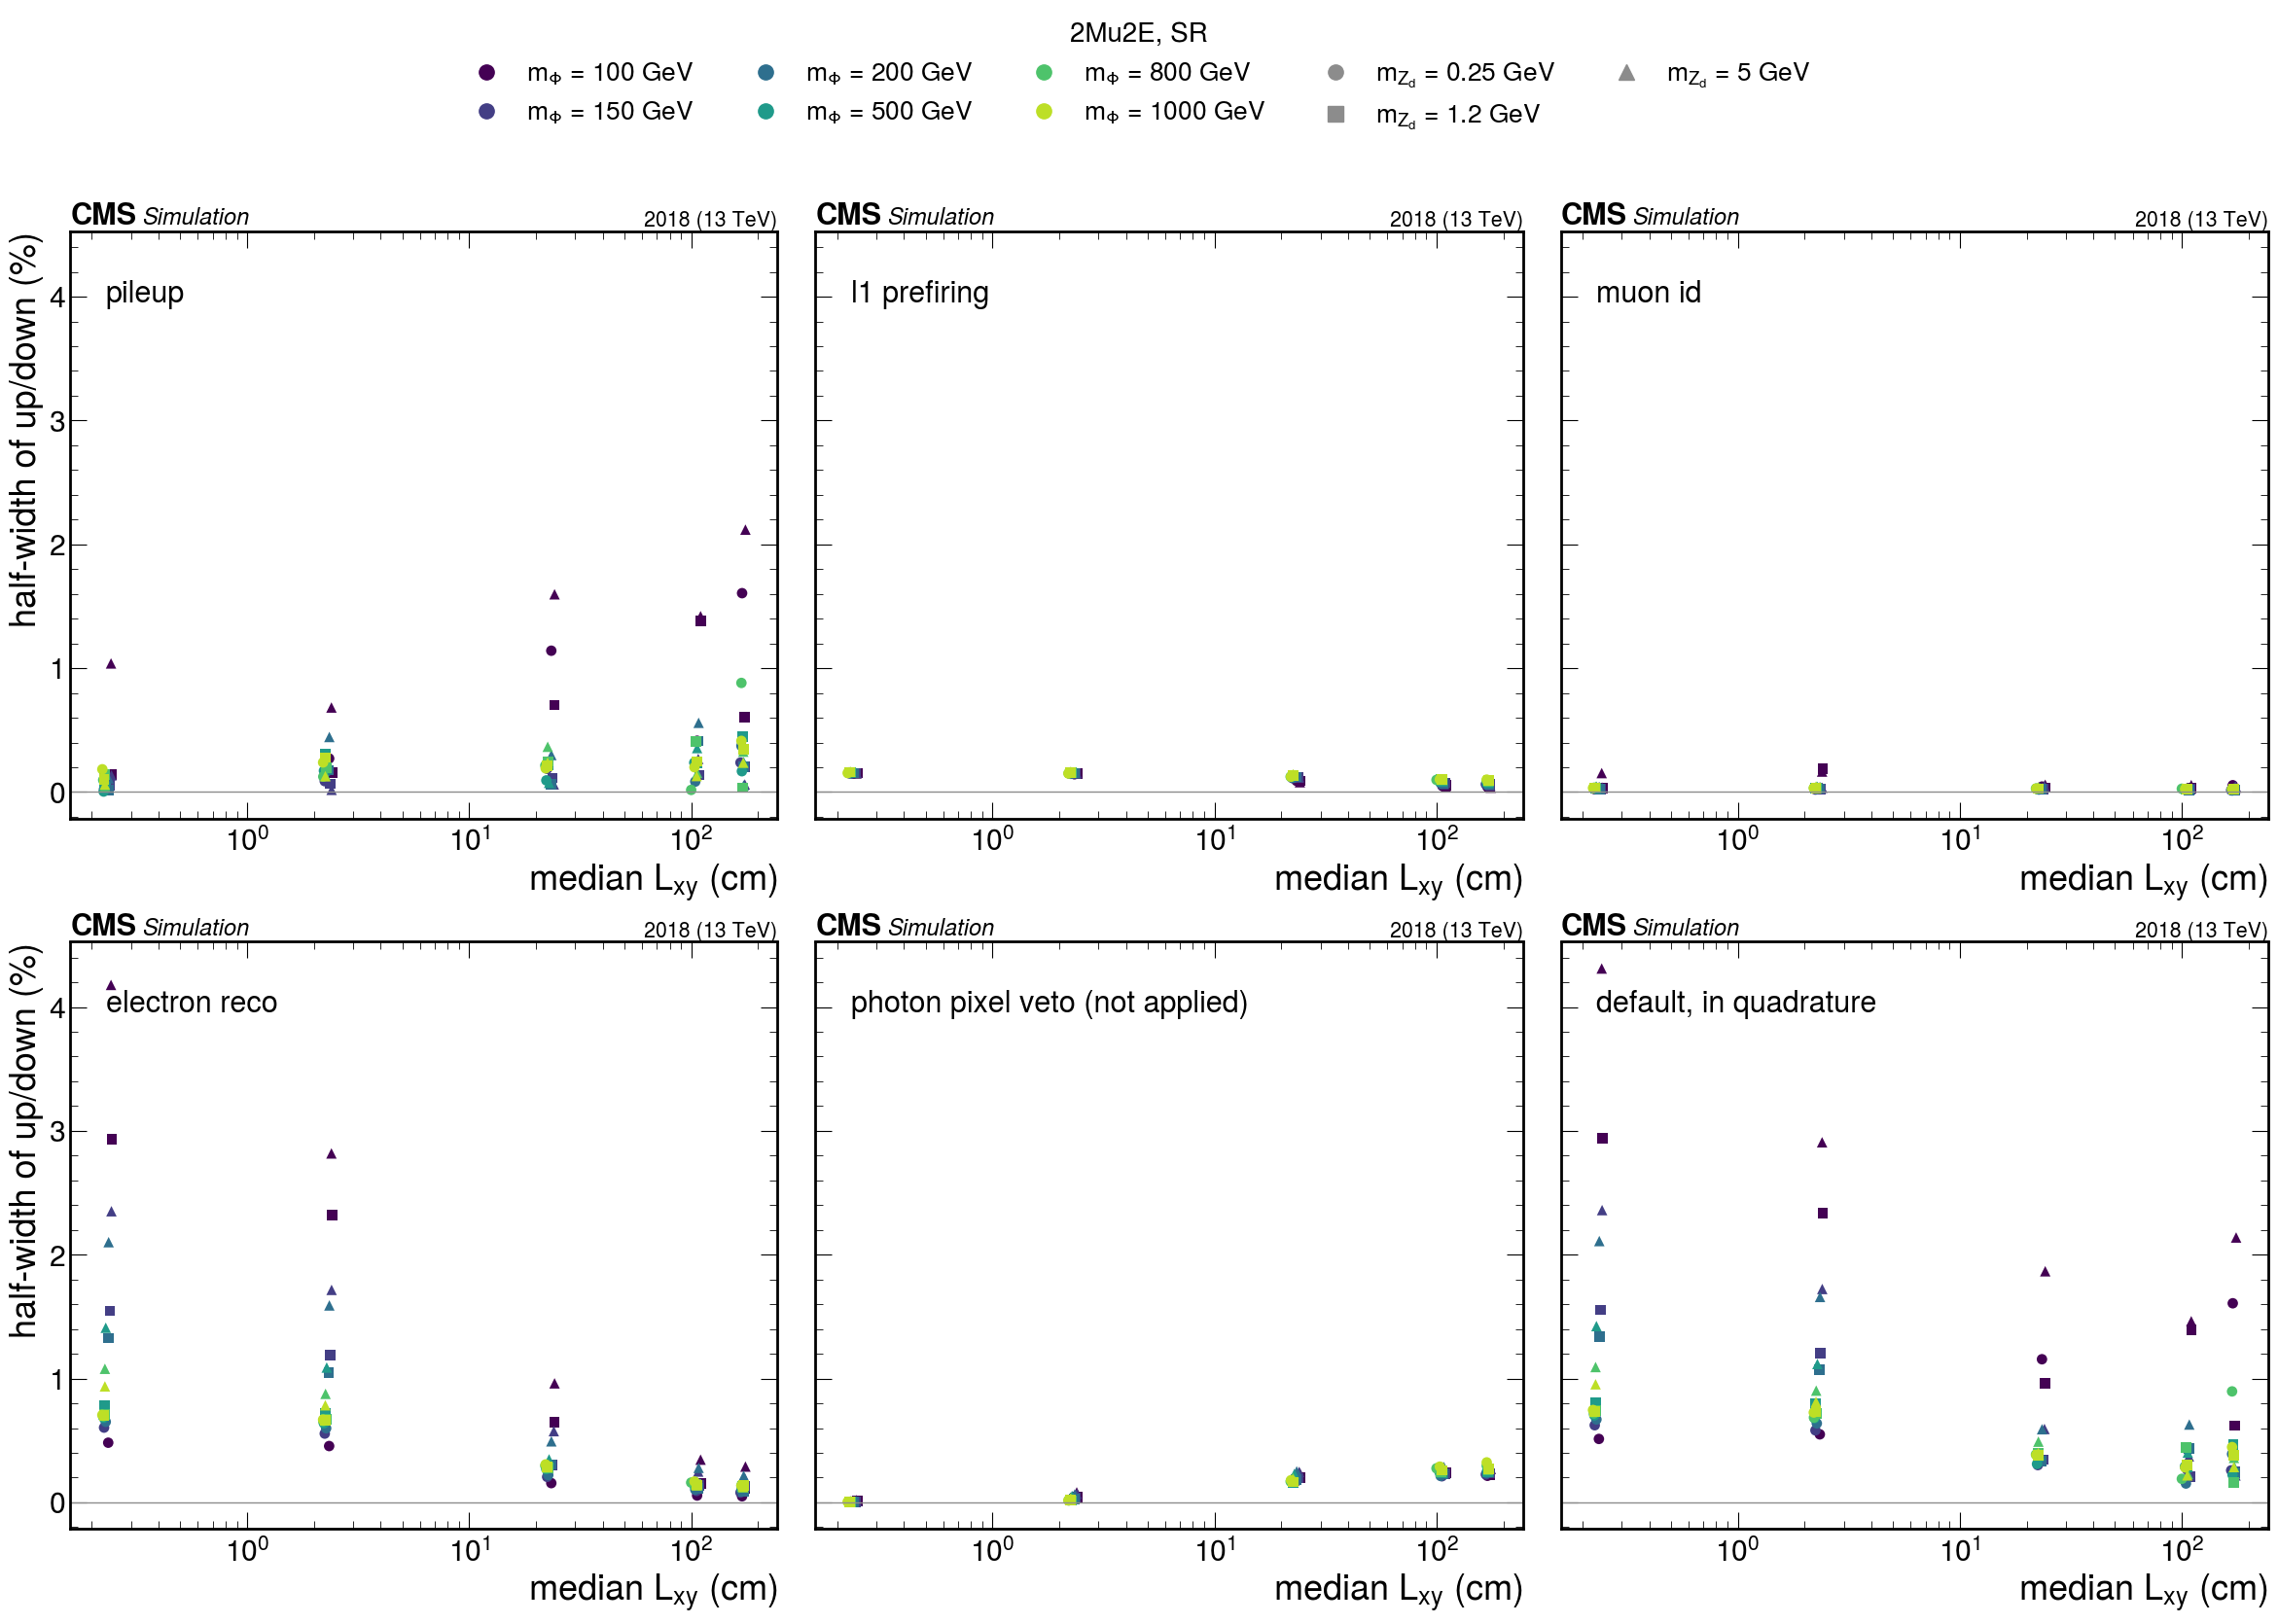

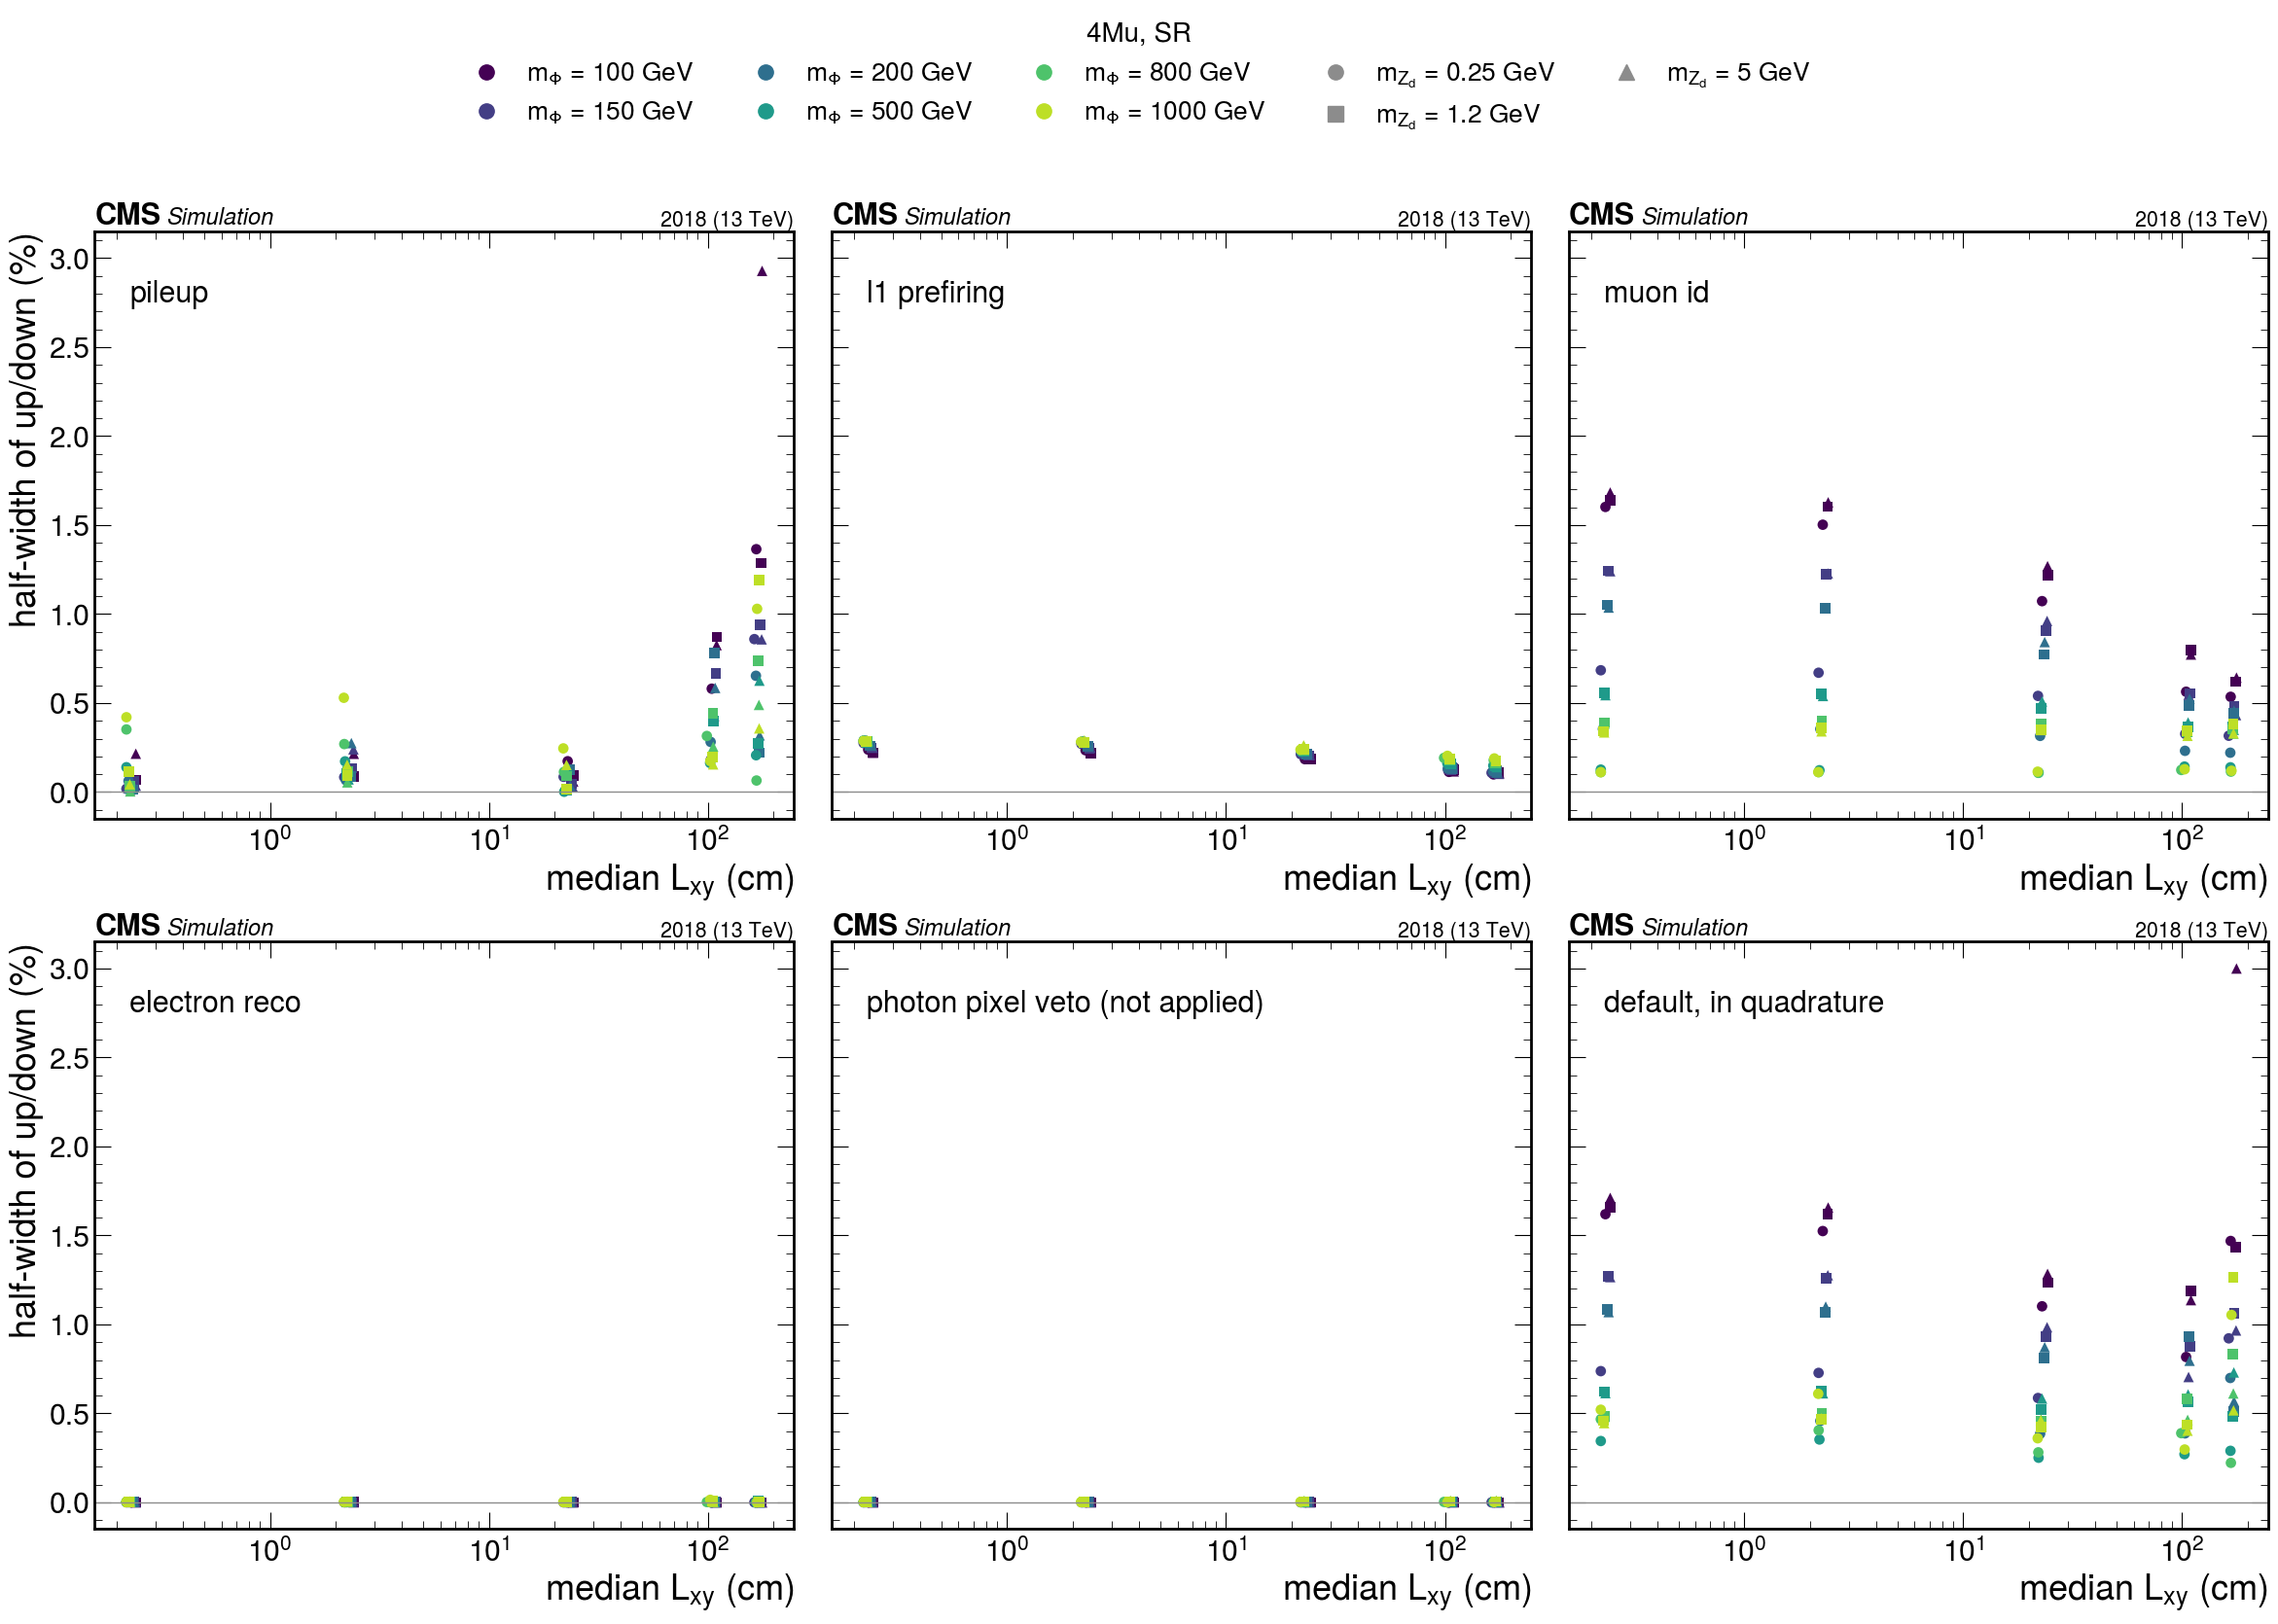

Half-width of the up/down variation over all points (min to max):
                                         2Mu2E                   4Mu
pileup                         0.00 to   2.12%       0.00 to   2.93%
l1_prefiring                   0.04 to   0.16%       0.10 to   0.29%
muon_id                        0.01 to   0.19%       0.11 to   1.68%
electron_reco                  0.05 to   4.18%       0.00 to   0.01%
photon_pixel_veto              0.00 to   0.32%       0.00 to   0.01%
quadrature                     0.15 to   4.31%       0.22 to   3.00%


In [6]:
half = {s: {n: 0.5 * abs(u[n][0] - u[n][1]) for n in PANELS} for s, u in unc.items()}
for s in half:
    half[s]["quadrature"] = np.sqrt(sum(half[s][n] ** 2 for n in NAMES))
for fs in study.FINAL_STATES:
    small_multiples(half, "half-width of up/down (%)", f"impact_uncertainties_{fs}", fs, 0.88, PANELS + ["quadrature"])
print("Half-width of the up/down variation over all points (min to max):")
ranges(half, PANELS + ["quadrature"], signed=False)

* **Pileup**: median 0.2% (2Mu2E) and 0.16% (4Mu); above 1% for 12 points, ten of them at
  $m_\Phi$ = 100 GeV, mostly at long lifetimes; at most 2.9%.
* **Prefiring** and **muon ID**: a few tenths of a percent at most, except the muon ID for
  4Mu at low mass (up to 1.7% at $m_\Phi$ = 100 GeV), where the J/$\psi$-based SFs below
  20 GeV carry larger uncertainties.
* **Electron reconstruction**: up to 4.2% for 2Mu2E at $m_\Phi$ = 100 GeV, from the 6%
  per-electron uncertainty of the SF below 20 GeV (0.6% above); below 1% everywhere else.
* **In quadrature**: 0.15 to 4.3% (2Mu2E, median 0.6%) and 0.2 to 3.0% (4Mu, median 0.6%).

For the datacards these become one lnN nuisance per correction, correlated between
the two channels and across signal points, next to the existing `lumi_13TeV`; the
values per point are in `tables/sr_correction_nuisances.csv`.

How precisely are these variations known? Each event's pileup weight changes by a
different factor under the up and down shifts, so the variation of a yield made of
$N$ events has a statistical uncertainty of about (spread of those factors)$/\sqrt{N_{\rm eff}}$.
`weight_pileup_halfwidth` is that per-event relative half-width, filled with the
nominal weights; its sum of squared weights gives $N_{\rm eff}$.

In [7]:
precision = {}
for s in SIGNALS:
    h = out[s]["hists"]["weight_pileup_halfwidth"][{"channel": sr(s), "syst": "nominal"}]
    w, w2 = h.values().sum(), h.variances().sum()
    n_eff = w ** 2 / w2 if w2 else 0
    m = study.binned_mean(h)
    spread = np.sqrt(np.sum((h.axes[0].centers - m) ** 2 * h.values()) / w)
    precision[s] = spread / np.sqrt(n_eff) if n_eff else np.inf
significant = [s for s in SIGNALS if half[s]["pileup"] > 2 * precision[s]]
print(f"{'signal point':34s} {'SR raw':>7s} {'pileup half-width':>18s} {'statistical precision':>22s}")
for s in SIGNALS:
    p = study.parse_point(s)
    if p["m_zd"] == 1.2 and p["m_phi"] in (200, 500, 1000):
        print(f"{s:34s} {study.raw(out[s], sr(s)):7d} {100 * half[s]['pileup']:17.2f}% {100 * precision[s]:21.2f}%")
print(f"pileup half-width above twice its statistical precision for {len(significant)} of {len(SIGNALS)} points")

signal point                        SR raw  pileup half-width  statistical precision
2Mu2E_200GeV_1p2GeV_0p048mm           8330              0.01%                  0.18%
2Mu2E_200GeV_1p2GeV_0p48mm           14670              0.18%                  0.13%
2Mu2E_200GeV_1p2GeV_4p8mm            12579              0.06%                  0.14%
2Mu2E_200GeV_1p2GeV_24p0mm            3597              0.41%                  0.27%
2Mu2E_200GeV_1p2GeV_48p0mm             484              0.20%                  0.66%
2Mu2E_500GeV_1p2GeV_0p019mm          73603              0.04%                  0.06%
2Mu2E_500GeV_1p2GeV_0p19mm           65415              0.30%                  0.06%
2Mu2E_500GeV_1p2GeV_1p9mm            52295              0.22%                  0.07%
2Mu2E_500GeV_1p2GeV_9p6mm            14747              0.23%                  0.13%
2Mu2E_500GeV_1p2GeV_19p0mm            5290              0.44%                  0.22%
2Mu2E_1000GeV_1p2GeV_0p0096mm        58392              0.10%    

With the full samples most variations are measured precisely: the pileup half-width is
above twice its statistical precision for 67 of the 180 points, and where it is not,
the variation itself is small (a few tenths of a percent). Of the 12 points above 1%,
the five 4Mu ones are 2.5 to 8 times their precision, so they are real features of those
samples; the seven 2Mu2E points at $m_\Phi$ = 100 GeV, with 133 to 1610 events in the SR,
are only 1.4 to 3 times theirs, so part of their variation is statistical.

In [8]:
# the per-point table, for the datacards
os.makedirs("tables", exist_ok=True)
path = os.path.join("tables", "sr_correction_nuisances.csv")
with open(path, "w", newline="") as f:
    writer = csv.writer(f)
    header = ["sample", "final_state", "m_phi_GeV", "m_zd_GeV", "ctau_mm", "median_lxy_cm", "sr_channel",
              "sr_raw_events", "sr_yield_uncorrected", "sr_yield_nominal"]
    for n in NAMES:
        header += [f"{n}_shift", f"{n}_kappa_up", f"{n}_kappa_down"]
    header += [f"{MONITORED}_shift_if_applied", f"{MONITORED}_kappa_up", f"{MONITORED}_kappa_down"]
    writer.writerow(header)
    for s in SIGNALS:
        p = study.parse_point(s)
        y = study.yields(out[s], sr(s))
        row = [s, p["final_state"], p["m_phi"], p["m_zd"], p["ctau"], LXY[s], sr(s), study.raw(out[s], sr(s)),
               f"{y['uncorrected']:.6g}", f"{y['nominal']:.6g}"]
        for n in NAMES + [MONITORED]:
            row += [f"{shift[s][n]:+.5f}", f"{1 + unc[s][n][0]:.5f}", f"{1 + unc[s][n][1]:.5f}"]
        writer.writerow(row)
print(f"wrote {path}: {len(SIGNALS)} points")

wrote tables/sr_correction_nuisances.csv: 180 points


## 4. The simulated backgrounds

The same comparison for the backgrounds, grouped as in `configs/composite_samples.yaml`.
The two DY samples overlap (DY$\to\ell\ell$ contains the muon pairs of DY$\to\mu\mu$) and
are never added; since which of the two the analysis uses is still open, the total is
given with each.

In [9]:
def group_yields(samples, channel):
    total = {}
    for s in samples:
        for k, v in study.yields(out[s], channel).items():
            total[k] = total.get(k, 0.0) + v
    return total, sum(study.raw(out[s], channel) for s in samples)

GROUPS = dict(study.BACKGROUNDS)
for total, groups in study.TOTAL_BACKGROUND.items():
    GROUPS[total] = [s for g in groups for s in study.BACKGROUNDS[g]]
print(f"{'group':20s} {'channel':9s} {'raw':>8s} {'uncorrected':>12s} {'corrected':>11s} {'change':>8s}   largest variations")
bkg_change = {}
for g, samples in GROUPS.items():
    for ch in CHANNELS:
        y, n_raw = group_yields(samples, ch)
        change = y["nominal"] / y["uncorrected"] - 1 if y["uncorrected"] else float("nan")
        bkg_change[(g, ch)] = change
        top = sorted(((abs(v / y["nominal"] - 1), k) for k, v in y.items()
                      if (k.endswith("Up") or k.endswith("Down")) and not k.startswith("with_") and y["nominal"]),
                     reverse=True)[:2]
        label = g.replace("$", "").replace("\\to", "->").replace("\\ell", "l").replace("\\mu", "mu").replace("t\\bar{t}", "ttbar").replace("total, ", "total ")
        print(f"{label:20s} {ch:9s} {n_raw:8d} {y['uncorrected']:12.4g} {y['nominal']:11.4g} {100 * change:+7.2f}%   "
              + ", ".join(f"{k} {100 * d:.1f}%" for d, k in top))

group                channel        raw  uncorrected   corrected   change   largest variations
DY->mumu             base      41175176    2.646e+07   2.623e+07   -0.89%   l1_prefiringUp 0.2%, l1_prefiringDown 0.2%
DY->mumu             2mu2e          519         1268        1248   -1.56%   pileupDown 0.4%, pileupUp 0.4%
DY->mumu             4mu            671        474.1         483   +1.86%   pileupUp 10.9%, pileupDown 10.3%
DY->mumu             2mu2e_sr       296        839.5       824.4   -1.80%   pileupUp 0.8%, pileupDown 0.4%
DY->mumu             4mu_sr         610          385       389.8   +1.24%   pileupUp 9.2%, pileupDown 8.0%
DY->ll               base       8009829    2.604e+07   2.581e+07   -0.89%   l1_prefiringUp 0.2%, l1_prefiringDown 0.2%
DY->ll               2mu2e          143        809.4       809.9   +0.06%   pileupUp 5.1%, pileupDown 4.3%
DY->ll               4mu            143        489.6       495.2   +1.15%   pileupUp 9.0%, pileupDown 7.4%
DY->ll               2m

The change of each background group in each channel, with the uncertainty of the default
corrections (their up/down half-widths added in quadrature) as error bars. One panel per
group; the last compares the two totals.

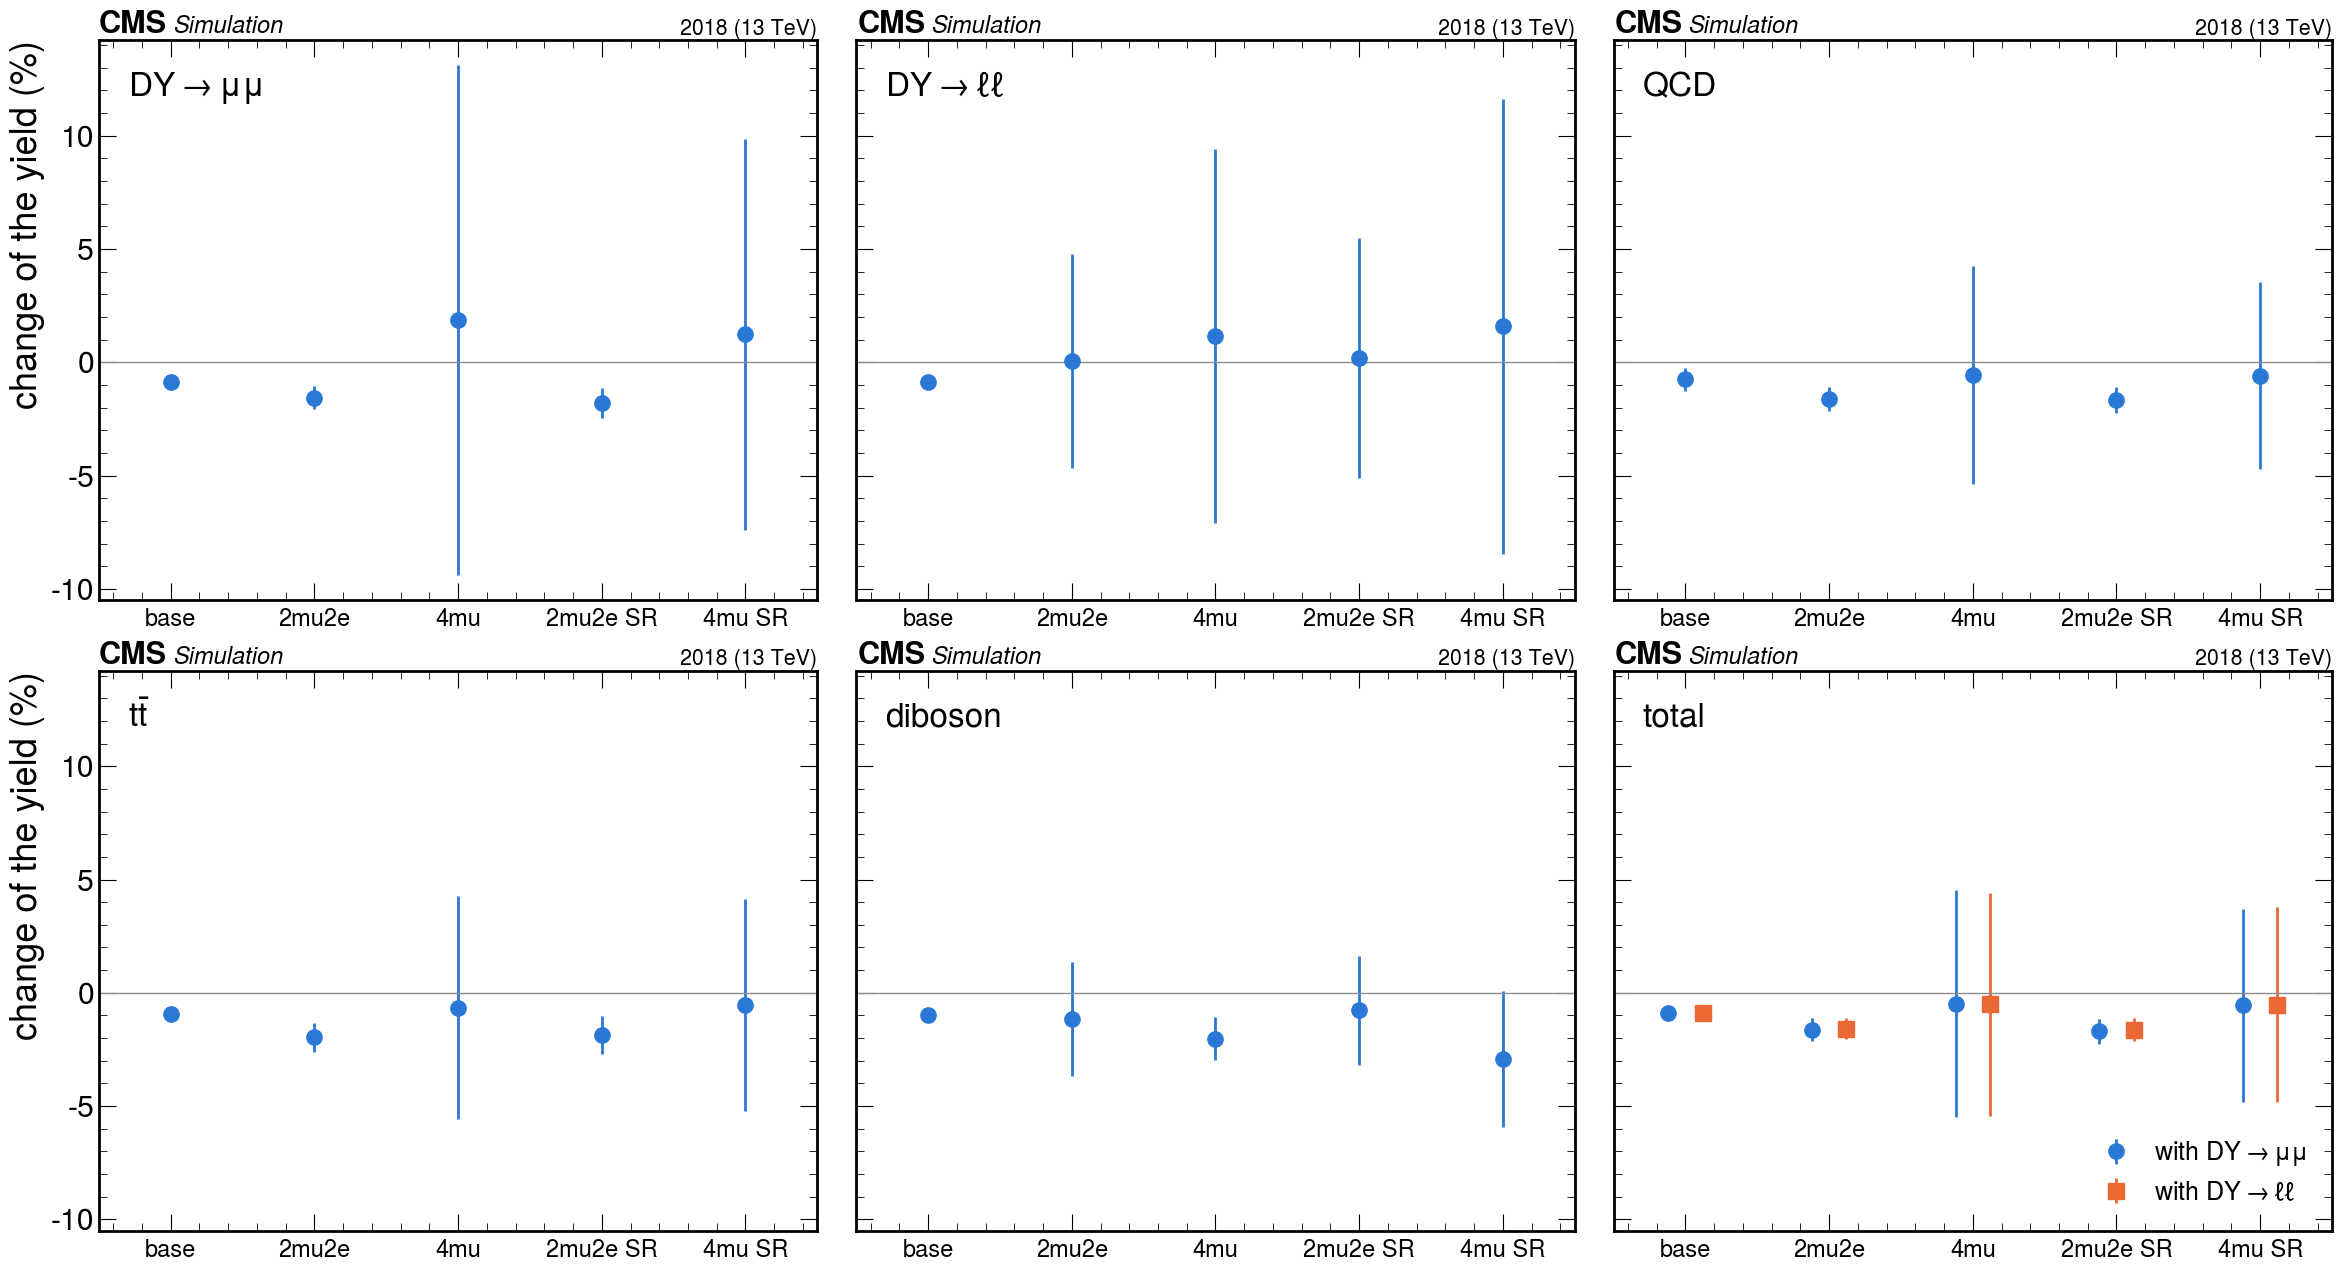

In [10]:
def change_and_unc(samples, channel):
    y, _ = group_yields(samples, channel)
    if not y["uncorrected"] or not y["nominal"]:
        return np.nan, np.nan
    unc = np.sqrt(sum((0.5 * (y[f"{n}Up"] - y[f"{n}Down"]) / y["nominal"]) ** 2 for n in NAMES))
    return 100 * (y["nominal"] / y["uncorrected"] - 1), 100 * unc

LABELS = {"base": "base", "2mu2e": "2mu2e", "4mu": "4mu", "2mu2e_sr": "2mu2e SR", "4mu_sr": "4mu SR"}
x = np.arange(len(CHANNELS))
fig, axs = plt.subplots(2, 3, figsize=(24, 13), sharey=True)
axs = axs.ravel()
for ax, g in zip(axs, study.BACKGROUNDS):
    vals = np.array([change_and_unc(study.BACKGROUNDS[g], ch) for ch in CHANNELS])
    ax.errorbar(x, vals[:, 0], yerr=vals[:, 1], fmt="o", ms=11, color=BLUE, elinewidth=2, capsize=0)
    ax.text(0.04, 0.90, g, transform=ax.transAxes, fontsize=24)
ax = axs[5]
for (total, groups), color, marker, dx in zip(study.TOTAL_BACKGROUND.items(), [BLUE, ORANGE], ["o", "s"], [-0.12, 0.12]):
    samples = [s for g in groups for s in study.BACKGROUNDS[g]]
    vals = np.array([change_and_unc(samples, ch) for ch in CHANNELS])
    ax.errorbar(x + dx, vals[:, 0], yerr=vals[:, 1], fmt=marker, ms=11, color=color, elinewidth=2, capsize=0,
                label=total.replace("total, ", "with "))
ax.text(0.04, 0.90, "total", transform=ax.transAxes, fontsize=24)
ax.legend(fontsize=18, loc="lower right")
for ax in axs:
    ax.axhline(0, color=GRAY, lw=1)
    ax.set_xticks(x, [LABELS[c] for c in CHANNELS], fontsize=17)
    ax.set_xlim(-0.5, len(CHANNELS) - 0.5)
for ax in (axs[0], axs[3]):
    ax.set_ylabel("change of the yield (%)")
plt.tight_layout()
study.cms_label(list(axs))
study.save(fig, "impact_backgrounds")
plt.show()

What each correction does to each background on its own: the `only_<name>` over
`uncorrected` yield, at `base` and in the two SRs.

In [11]:
def short(g):
    return g.replace("$", "").replace("\\to", "->").replace("\\ell", "l").replace("\\mu", "mu").replace("t\\bar{t}", "ttbar")

print(f"{'group':12s} {'channel':9s}" + "".join(f"{n:>15s}" for n in NAMES))
for g, samples in study.BACKGROUNDS.items():
    for ch in ["base", "2mu2e_sr", "4mu_sr"]:
        y, _ = group_yields(samples, ch)
        cols = "".join(f"{100 * (y[f'only_{n}'] / y['uncorrected'] - 1):+14.2f}%" for n in NAMES)
        print(f"{short(g) if ch == 'base' else '':12s} {ch:9s}{cols}")

group        channel           pileup   l1_prefiring        muon_id  electron_reco
DY->mumu     base              -0.02%         -0.64%         -0.23%         -0.00%
             2mu2e_sr          -0.61%         -0.66%         -0.28%         -0.28%
             4mu_sr            +2.48%         -0.71%         -0.49%         -0.00%
DY->ll       base              -0.02%         -0.64%         -0.23%         -0.00%
             2mu2e_sr          +1.65%         -0.58%         -0.22%         -0.64%
             4mu_sr            +2.83%         -0.75%         -0.45%         +0.00%
QCD          base              +0.13%         -0.64%         -0.28%         +0.03%
             2mu2e_sr          -0.09%         -0.64%         -0.20%         -0.75%
             4mu_sr            +1.13%         -0.80%         -1.01%         +0.12%
ttbar        base              +0.00%         -0.66%         -0.22%         -0.07%
             2mu2e_sr          -0.11%         -0.67%         -0.30%         -0.78%
    

* At the `base` selection the corrections lower every background by 0.8 to 1.0%
  (DY $-0.9$%, QCD $-0.8$%, $t\bar t$ $-1.0$%, diboson $-1.0$%): the prefiring weight
  takes 0.6 to 0.7% and the muon ID SF 0.2 to 0.3%, while pileup and the electron SF do
  almost nothing. The uncertainties are a few tenths of a percent.
* In the 2Mu2E channels the electron reconstruction SF adds $-0.6$ to $-0.8$%; the total
  background in `2mu2e_sr` goes down by 1.7%, with either DY sample.
* In the 4Mu channels the total goes down by 0.5%. The pileup shifts and their variations
  are large there (shifts of $-1.5$ to $+2.8$%, variations of 4 to 11%) because a few
  simulated events with large weights dominate those channels (QCD bins with large cross
  sections and few events, the DY generator weights): they say more about the statistics
  of the weights than about the pileup modelling.
* The QCD skims make up nine tenths of the SR background, and the SR backgrounds are as
  large as the categories' because the SR selections do not remove the non-isolated and
  prompt lepton jets (section 6).

## 5. Variations on a distribution

Every histogram carries the weight categories, so a shape can be shown with its band.
Here the invariant mass of the two leading lepton jets in the SR for one point, with
the default variations added in quadrature bin by bin.

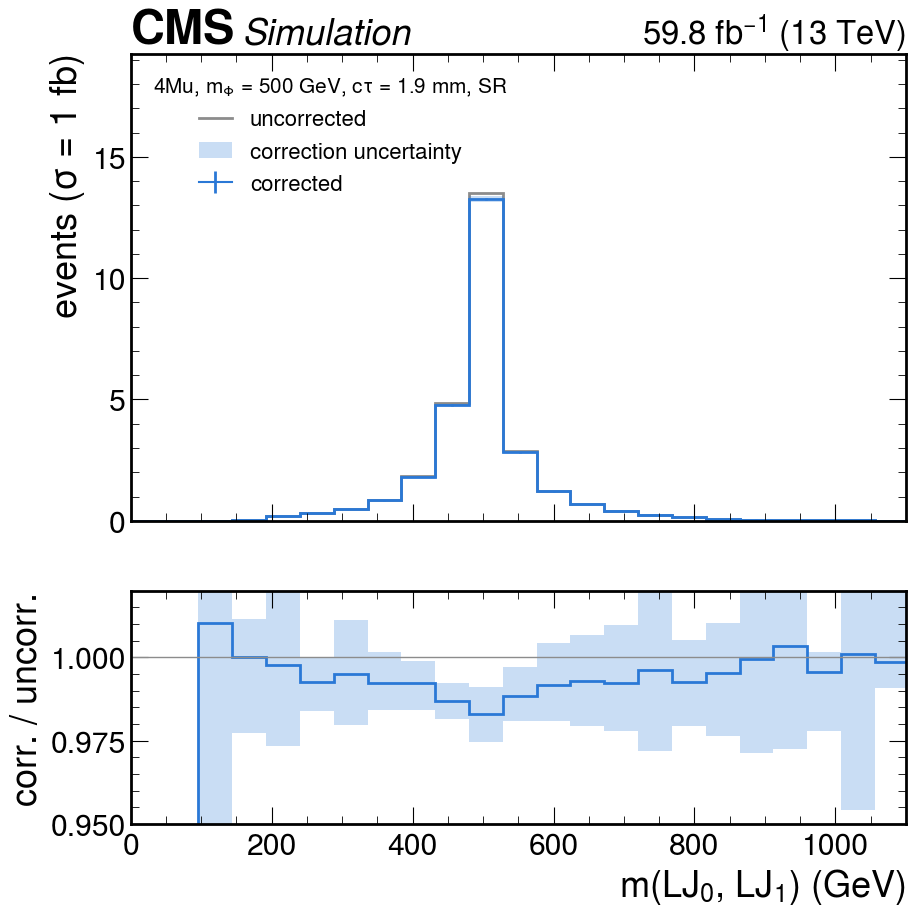

In [12]:
def mass_plot(s, figname):
    ch = sr(s)
    h = out[s]["hists"]["lj_lj_invmass"][{"channel": ch}]
    rebin = hist.rebin(4)
    nominal_h = h[{"syst": "nominal"}][rebin]
    nominal = nominal_h.values()
    up2, down2 = np.zeros_like(nominal), np.zeros_like(nominal)
    for name in NAMES:
        for shift_name in (f"{name}Up", f"{name}Down"):
            d = h[{"syst": shift_name}][rebin].values() - nominal
            up2 += np.where(d > 0, d, 0) ** 2
            down2 += np.where(d < 0, d, 0) ** 2
    axis = nominal_h.axes[0]

    def values_hist(values):
        out_h = hist.Hist(axis)
        out_h.view()[:] = values
        return out_h

    unc_vals = h[{"syst": "uncorrected"}][rebin].values()
    def over_unc(values):
        return np.divide(values, unc_vals, out=np.full_like(values, np.nan), where=unc_vals > 0)

    p = study.parse_point(s)
    title = rf"{p['final_state']}, $m_\Phi$ = {p['m_phi']:g} GeV, $c\tau$ = {p['ctau']:g} mm, SR"
    fig, (ax, rax) = plt.subplots(2, 1, figsize=(10, 10), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    hep.histplot(h[{"syst": "uncorrected"}][rebin], ax=ax, color=GRAY, lw=2, yerr=False, label="uncorrected", flow="none")
    hep.histplot(nominal_h, ax=ax, color=BLUE, lw=2, label="corrected", flow="none")
    study.band(ax, values_hist(nominal + np.sqrt(up2)), values_hist(nominal - np.sqrt(down2)), BLUE,
               label="correction uncertainty")
    ax.set_xlabel("")
    ax.set_ylim(0, 1.45 * nominal.max())
    ax.set_ylabel(r"events ($\sigma$ = 1 fb)")
    ax.legend(fontsize=16, title=title, title_fontsize=15, loc="upper left")
    study.band(rax, values_hist(over_unc(nominal + np.sqrt(up2))), values_hist(over_unc(nominal - np.sqrt(down2))), BLUE)
    hep.histplot(values_hist(over_unc(nominal)), ax=rax, color=BLUE, lw=2, yerr=False, flow="none")
    rax.axhline(1, color=GRAY, lw=1)
    rax.set_ylim(0.95, 1.02)
    rax.set_xlim(0, 2.2 * p["m_phi"])
    rax.set_xlabel(r"$m$(LJ$_0$, LJ$_1$) (GeV)")
    rax.set_ylabel("corr. / uncorr.")
    study.cms_label(ax, lumi=study.LUMI_2018)
    study.save(fig, figname)
    plt.show()

mass_plot("4Mu_500GeV_1p2GeV_1p9mm", "impact_mass_syst")

## 6. A remark on the SR definition

The SR selections ask for isolated and displaced lepton jets through object cuts on
`mu_ljs` and `egm_ljs`, but the event cuts that define the categories (`>=2 LJs`,
`4mu`, `2mu2e`, `LJ-LJ dPhi > 2`) count `ljs`, which those object cuts do not slim.
The counts show it: the SR differs from the corresponding category only by the
$\Delta\phi$ cut.

In [13]:
for s in ["2Mu2E_500GeV_1p2GeV_1p9mm", "4Mu_500GeV_1p2GeV_1p9mm"]:
    for ch in (["2mu2e", "2mu2e_sr"] if s.startswith("2Mu") else ["4mu", "4mu_sr"]):
        rows = out[s]["cutflow"][ch].rows
        print(f"{s:28s} {ch:9s}", " | ".join(f"{c}: {r['raw']}" for c, r in list(rows.items())[-3:]))

2Mu2E_500GeV_1p2GeV_1p9mm    2mu2e     all cosAlpha(mu, mu) > -0.99: 66169 | >=2 LJs: 53062 | 2mu2e: 52759
2Mu2E_500GeV_1p2GeV_1p9mm    2mu2e_sr  >=2 LJs: 53062 | LJ-LJ dPhi > 2: 52523 | 2mu2e: 52295
4Mu_500GeV_1p2GeV_1p9mm      4mu       all cosAlpha(mu, mu) > -0.99: 199151 | >=2 LJs: 175045 | 4mu: 116621
4Mu_500GeV_1p2GeV_1p9mm      4mu_sr    >=2 LJs: 175045 | LJ-LJ dPhi > 2: 172707 | 4mu: 115268


This is outside the scope of the corrections, but it matters for how the corrections
are read: the SR yields above are yields *before* the isolation and displacement
requirements, and the isolation is precisely where the jet corrections enter
(notebook 02, section 4). It is also why the simulated backgrounds in `2mu2e_sr` and
`4mu_sr` above are as large as in the categories.

## Summary

* The default corrections change the SR signal yields by $-2.2$ to $+0.7$% (2Mu2E,
  median $-0.7$%) and $-1.8$ to $+0.2$% (4Mu, median $-1.4$%), mostly through the L1
  prefiring weight and, for 4Mu at low mass, the muon ID SF. With the background fixed, a
  limit on the cross section scales as the inverse of the signal yield, so the expected
  limits move by the same fraction.
* Their uncertainties add up to 0.15 to 4.3% (2Mu2E) and 0.2 to 3.0% (4Mu) per point,
  with a median of 0.6%; the extremes are all at $m_\Phi$ = 100 GeV. The values per point
  are in `tables/sr_correction_nuisances.csv`, ready to enter the datacards as one lnN
  nuisance per correction.
* Every simulated background goes down by 0.8 to 1.0% at the `base` selection, and the
  total by 1.7% (`2mu2e_sr`) and 0.5% (`4mu_sr`) in the SRs, with either DY sample.
* The photon pixel-veto SF would have been the largest correction, up to $-5.6$% on the
  displaced 2Mu2E points, which is why it stays out of the default set until our "photons"
  are understood.
* These numbers cover only the corrections that exist. The efficiencies without a standard
  correction (the trigger, DSA muons, displaced and close-by leptons; notebook 02) are
  expected to dominate the systematic uncertainty and still have to be measured.